# Personalized Chakra-Based Yoga Flow Recommender — Practical Checkpoint 2

This notebook extends Checkpoint 1 by **testing** the recommender.

**Project question:** Does a rule-based personalized ranking using chakra, experience level, body focus, and goal produce recommendations that match a user's stated preferences better than a chakra-only baseline?

**Important clarification from Checkpoint 1 feedback:** the personalized method is a **scoring-rule method**. It has not learned from training data and should not be described as a trained machine-learning model.

The chakra labels are wellness/yoga categories for recommendation purposes and are not medical predictions.


## 1. Data and source validation

The starter dataset still contains 21 records. Each record now includes a direct Tummee pose page rather than only linking to the Tummee home page.

Some records intentionally share a source page because they are the same physical pose used under a different recommendation category (for example, Easy Pose and Child's Pose).


In [1]:
import pandas as pd

columns = ['Pose', 'Chakra', 'Level', 'Body Focus', 'Goal', 'Minutes', 'Source']
poses = [['Mountain Pose', 'Root', 'Beginner', 'Full Body', 'Grounding', 2, 'https://www.tummee.com/yoga-poses/mountain-pose'], ['Warrior I', 'Root', 'Beginner', 'Legs', 'Strength', 3, 'https://www.tummee.com/yoga-poses/warrior-pose'], ['Garland Pose', 'Root', 'Beginner', 'Hips', 'Grounding', 3, 'https://www.tummee.com/yoga-poses/garland-pose'], ["Child's Pose", 'Root', 'Beginner', 'Hips', 'Relaxation', 3, 'https://www.tummee.com/yoga-poses/child-pose'], ['Bound Angle Pose', 'Sacral', 'Beginner', 'Hips', 'Flexibility', 3, 'https://www.tummee.com/yoga-poses/bound-angle-pose'], ['Low Lunge', 'Sacral', 'Beginner', 'Hips', 'Flexibility', 3, 'https://www.tummee.com/yoga-poses/low-lunge-pose'], ['Cat-Cow', 'Sacral', 'Beginner', 'Spine', 'Relaxation', 2, 'https://www.tummee.com/yoga-poses/cat-and-cow'], ['Boat Pose', 'Solar Plexus', 'Intermediate', 'Core', 'Strength', 3, 'https://www.tummee.com/yoga-poses/boat-pose'], ['Plank Pose', 'Solar Plexus', 'Beginner', 'Core', 'Strength', 2, 'https://www.tummee.com/yoga-poses/plank-pose'], ['Warrior II', 'Solar Plexus', 'Beginner', 'Legs', 'Strength', 3, 'https://www.tummee.com/yoga-poses/warrior-pose-ii'], ['Cobra Pose', 'Heart', 'Beginner', 'Chest', 'Energy', 2, 'https://www.tummee.com/yoga-poses/cobra-pose'], ['Bridge Pose', 'Heart', 'Beginner', 'Chest', 'Relaxation', 3, 'https://www.tummee.com/yoga-poses/bridge-pose'], ['Camel Pose', 'Heart', 'Intermediate', 'Chest', 'Flexibility', 3, 'https://www.tummee.com/yoga-poses/camel-pose'], ['Fish Pose', 'Throat', 'Intermediate', 'Neck/Chest', 'Flexibility', 3, 'https://www.tummee.com/yoga-poses/fish-pose'], ['Supported Shoulderstand', 'Throat', 'Intermediate', 'Shoulders', 'Balance', 4, 'https://www.tummee.com/yoga-poses/supported-shoulderstand-pose'], ['Easy Pose', 'Third Eye', 'Beginner', 'Full Body', 'Meditation', 3, 'https://www.tummee.com/yoga-poses/easy-pose'], ["Child's Pose (Meditative)", 'Third Eye', 'Beginner', 'Back', 'Meditation', 3, 'https://www.tummee.com/yoga-poses/child-pose'], ['Tree Pose', 'Third Eye', 'Beginner', 'Legs', 'Balance', 3, 'https://www.tummee.com/yoga-poses/tree-pose'], ['Lotus Pose', 'Crown', 'Advanced', 'Hips', 'Meditation', 4, 'https://www.tummee.com/yoga-poses/lotus-pose'], ['Easy Pose (Crown)', 'Crown', 'Beginner', 'Full Body', 'Meditation', 3, 'https://www.tummee.com/yoga-poses/easy-pose'], ['Corpse Pose', 'Crown', 'Beginner', 'Full Body', 'Relaxation', 4, 'https://www.tummee.com/yoga-poses/corpse-pose']]
df = pd.DataFrame(poses, columns=columns)

print("Dataset size:", len(df), "records")
display(df)


Dataset size: 21 records


,Pose,Chakra,Level,Body Focus,Goal,Minutes,Source
0,Mountain Pose,Root,Beginner,Full Body,Grounding,2,https://www.tummee.com/yoga-poses/mountain-pose
1,Warrior I,Root,Beginner,Legs,Strength,3,https://www.tummee.com/yoga-poses/warrior-pose
2,Garland Pose,Root,Beginner,Hips,Grounding,3,https://www.tummee.com/yoga-poses/garland-pose
3,Child's Pose,Root,Beginner,Hips,Relaxation,3,https://www.tummee.com/yoga-poses/child-pose
4,Bound Angle Pose,Sacral,Beginner,Hips,Flexibility,3,https://www.tummee.com/yoga-poses/bound-angle-...
5,Low Lunge,Sacral,Beginner,Hips,Flexibility,3,https://www.tummee.com/yoga-poses/low-lunge-pose
6,Cat-Cow,Sacral,Beginner,Spine,Relaxation,2,https://www.tummee.com/yoga-poses/cat-and-cow
7,Boat Pose,Solar Plexus,Intermediate,Core,Strength,3,https://www.tummee.com/yoga-poses/boat-pose
8,Plank Pose,Solar Plexus,Beginner,Core,Strength,2,https://www.tummee.com/yoga-poses/plank-pose
9,Warrior II,Solar Plexus,Beginner,Legs,Strength,3,https://www.tummee.com/yoga-poses/warrior-pose-ii


## 2. Methods

### Baseline
The baseline uses only the selected chakra and returns up to four records in dataset order.

### Personalized scoring
The personalized method first filters to the selected chakra. Every candidate begins with 1 point for being in that chakra, then receives:
- +1 for matching experience level
- +1 for matching body focus
- +1 for matching goal

Higher scores rank first. Minutes are used only as a tie-breaker.

This is deterministic rule-based ranking, not a model learned from data.


In [2]:
def baseline_recommend(chakra, n=4):
    matches = df[df["Chakra"].str.lower() == chakra.lower()]
    return matches.head(n)[["Pose", "Chakra", "Level", "Body Focus", "Goal", "Source"]]

def personalized_recommend(chakra, level, body_focus, goal, n=4):
    candidates = df[df["Chakra"].str.lower() == chakra.lower()].copy()

    candidates["Score"] = 1
    candidates["Score"] += (candidates["Level"].str.lower() == level.lower()).astype(int)
    candidates["Score"] += (candidates["Body Focus"].str.lower() == body_focus.lower()).astype(int)
    candidates["Score"] += (candidates["Goal"].str.lower() == goal.lower()).astype(int)

    return candidates.sort_values(
        ["Score", "Minutes"], ascending=[False, True]
    ).head(n)[["Pose", "Chakra", "Level", "Body Focus", "Goal", "Score", "Source"]]


## 3. New test profiles

Both methods are tested on the same five profiles. These are separate from the original Checkpoint 1 sample (`Root / Beginner / Hips / Grounding`).


In [3]:
test_profiles = [
    {"name": "Profile 1", "chakra": "Root", "level": "Beginner", "body_focus": "Hips", "goal": "Relaxation"},
    {"name": "Profile 2", "chakra": "Sacral", "level": "Beginner", "body_focus": "Hips", "goal": "Flexibility"},
    {"name": "Profile 3", "chakra": "Solar Plexus", "level": "Intermediate", "body_focus": "Core", "goal": "Strength"},
    {"name": "Profile 4", "chakra": "Heart", "level": "Beginner", "body_focus": "Chest", "goal": "Relaxation"},
    {"name": "Profile 5", "chakra": "Third Eye", "level": "Beginner", "body_focus": "Legs", "goal": "Balance"},
]
display(pd.DataFrame(test_profiles))


,name,chakra,level,body_focus,goal
0,Profile 1,Root,Beginner,Hips,Relaxation
1,Profile 2,Sacral,Beginner,Hips,Flexibility
2,Profile 3,Solar Plexus,Intermediate,Core,Strength
3,Profile 4,Heart,Beginner,Chest,Relaxation
4,Profile 5,Third Eye,Beginner,Legs,Balance


## 4. Automatic preference-match test

For each recommended pose, the test counts how many of the three personalization fields match the profile: **level, body focus, and goal**. Chakra is not counted because both methods already filter by chakra.

The match rate is:

`matching preference fields / all preference fields across returned recommendations`

This test measures preference matching only. It does **not** prove that a recommendation is useful to a person.


In [4]:
def preference_match_rate(recommendations, profile):
    if len(recommendations) == 0:
        return 0.0

    matches = 0
    total = len(recommendations) * 3

    for _, pose in recommendations.iterrows():
        matches += int(pose["Level"].lower() == profile["level"].lower())
        matches += int(pose["Body Focus"].lower() == profile["body_focus"].lower())
        matches += int(pose["Goal"].lower() == profile["goal"].lower())

    return round(100 * matches / total, 1)

comparison_rows = []

for profile in test_profiles:
    baseline = baseline_recommend(profile["chakra"])
    personalized = personalized_recommend(
        profile["chakra"], profile["level"], profile["body_focus"], profile["goal"]
    )

    comparison_rows.append({
        "Profile": profile["name"],
        "Baseline Top Pick": baseline.iloc[0]["Pose"] if len(baseline) else "None",
        "Personalized Top Pick": personalized.iloc[0]["Pose"] if len(personalized) else "None",
        "Baseline Match Rate (%)": preference_match_rate(baseline, profile),
        "Personalized Match Rate (%)": preference_match_rate(personalized, profile),
        "Baseline # Poses": len(baseline),
        "Personalized # Poses": len(personalized),
    })

comparison = pd.DataFrame(comparison_rows)
display(comparison)

print("Average baseline match rate:", round(comparison["Baseline Match Rate (%)"].mean(), 1), "%")
print("Average personalized match rate:", round(comparison["Personalized Match Rate (%)"].mean(), 1), "%")


,Profile,Baseline Top Pick,Personalized Top Pick,Baseline Match Rate (%),Personalized Match Rate (%),Baseline # Poses,Personalized # Poses
0,Profile 1,Mountain Pose,Child's Pose,58.3,58.3,4,4
1,Profile 2,Bound Angle Pose,Bound Angle Pose,77.8,77.8,3,3
2,Profile 3,Boat Pose,Boat Pose,66.7,66.7,3,3
3,Profile 4,Cobra Pose,Bridge Pose,66.7,66.7,3,3
4,Profile 5,Easy Pose,Tree Pose,55.6,55.6,3,3


Average baseline match rate: 65.0 %
Average personalized match rate: 65.0 %


## 5. Example output from both methods

This cell prints both recommendation lists for each profile so the actual rankings can be inspected, not just the summary percentages.


In [5]:
for profile in test_profiles:
    print("\n" + "=" * 70)
    print(profile["name"], "-", profile["chakra"], "/", profile["level"], "/", profile["body_focus"], "/", profile["goal"])

    print("\nBASELINE")
    display(baseline_recommend(profile["chakra"]))

    print("PERSONALIZED")
    display(personalized_recommend(
        profile["chakra"], profile["level"], profile["body_focus"], profile["goal"]
    ))



Profile 1 - Root / Beginner / Hips / Relaxation

BASELINE


,Pose,Chakra,Level,Body Focus,Goal,Source
0,Mountain Pose,Root,Beginner,Full Body,Grounding,https://www.tummee.com/yoga-poses/mountain-pose
1,Warrior I,Root,Beginner,Legs,Strength,https://www.tummee.com/yoga-poses/warrior-pose
2,Garland Pose,Root,Beginner,Hips,Grounding,https://www.tummee.com/yoga-poses/garland-pose
3,Child's Pose,Root,Beginner,Hips,Relaxation,https://www.tummee.com/yoga-poses/child-pose


PERSONALIZED


,Pose,Chakra,Level,Body Focus,Goal,Score,Source
3,Child's Pose,Root,Beginner,Hips,Relaxation,4,https://www.tummee.com/yoga-poses/child-pose
2,Garland Pose,Root,Beginner,Hips,Grounding,3,https://www.tummee.com/yoga-poses/garland-pose
0,Mountain Pose,Root,Beginner,Full Body,Grounding,2,https://www.tummee.com/yoga-poses/mountain-pose
1,Warrior I,Root,Beginner,Legs,Strength,2,https://www.tummee.com/yoga-poses/warrior-pose



Profile 2 - Sacral / Beginner / Hips / Flexibility

BASELINE


...

,Pose,Chakra,Level,Body Focus,Goal,Score,Source
11,Bridge Pose,Heart,Beginner,Chest,Relaxation,4,https://www.tummee.com/yoga-poses/bridge-pose
10,Cobra Pose,Heart,Beginner,Chest,Energy,3,https://www.tummee.com/yoga-poses/cobra-pose
12,Camel Pose,Heart,Intermediate,Chest,Flexibility,2,https://www.tummee.com/yoga-poses/camel-pose



Profile 5 - Third Eye / Beginner / Legs / Balance

BASELINE


,Pose,Chakra,Level,Body Focus,Goal,Source
15,Easy Pose,Third Eye,Beginner,Full Body,Meditation,https://www.tummee.com/yoga-poses/easy-pose
16,Child's Pose (Meditative),Third Eye,Beginner,Back,Meditation,https://www.tummee.com/yoga-poses/child-pose
17,Tree Pose,Third Eye,Beginner,Legs,Balance,https://www.tummee.com/yoga-poses/tree-pose


PERSONALIZED


,Pose,Chakra,Level,Body Focus,Goal,Score,Source
17,Tree Pose,Third Eye,Beginner,Legs,Balance,4,https://www.tummee.com/yoga-poses/tree-pose
15,Easy Pose,Third Eye,Beginner,Full Body,Meditation,2,https://www.tummee.com/yoga-poses/easy-pose
16,Child's Pose (Meditative),Third Eye,Beginner,Back,Meditation,2,https://www.tummee.com/yoga-poses/child-pose


## 6. Simulated reviewer exercise (illustrative only)

The three response sets below are hypothetical examples, **not feedback collected from real people**. They should not be reported as human-subject evaluation.


In [6]:
reviewer_results = pd.DataFrame([
    {"Reviewer": "Reviewer 1", "Profile": "Profile 1", "Choice": "Personalized"},
    {"Reviewer": "Reviewer 1", "Profile": "Profile 2", "Choice": "Tie"},
    {"Reviewer": "Reviewer 1", "Profile": "Profile 3", "Choice": "Tie"},
    {"Reviewer": "Reviewer 1", "Profile": "Profile 4", "Choice": "Personalized"},
    {"Reviewer": "Reviewer 1", "Profile": "Profile 5", "Choice": "Personalized"},

    {"Reviewer": "Reviewer 2", "Profile": "Profile 1", "Choice": "Personalized"},
    {"Reviewer": "Reviewer 2", "Profile": "Profile 2", "Choice": "Tie"},
    {"Reviewer": "Reviewer 2", "Profile": "Profile 3", "Choice": "Tie"},
    {"Reviewer": "Reviewer 2", "Profile": "Profile 4", "Choice": "Personalized"},
    {"Reviewer": "Reviewer 2", "Profile": "Profile 5", "Choice": "Personalized"},

    {"Reviewer": "Reviewer 3", "Profile": "Profile 1", "Choice": "Personalized"},
    {"Reviewer": "Reviewer 3", "Profile": "Profile 2", "Choice": "Tie"},
    {"Reviewer": "Reviewer 3", "Profile": "Profile 3", "Choice": "Tie"},
    {"Reviewer": "Reviewer 3", "Profile": "Profile 4", "Choice": "Baseline"},
    {"Reviewer": "Reviewer 3", "Profile": "Profile 5", "Choice": "Personalized"},
])

display(reviewer_results)

,Reviewer,Profile,Choice
0,Reviewer 1,Profile 1,Personalized
1,Reviewer 1,Profile 2,Tie
2,Reviewer 1,Profile 3,Tie
3,Reviewer 1,Profile 4,Personalized
4,Reviewer 1,Profile 5,Personalized
5,Reviewer 2,Profile 1,Personalized
6,Reviewer 2,Profile 2,Tie
7,Reviewer 2,Profile 3,Tie
8,Reviewer 2,Profile 4,Personalized
9,Reviewer 2,Profile 5,Personalized


In [7]:
# Run this AFTER entering reviewer choices.
completed_reviews = reviewer_results[reviewer_results["Choice"].str.strip() != ""]

if len(completed_reviews) == 0:
    print("No simulated judgments entered.")
else:
    print("Simulated judgments:", len(completed_reviews))
    display(completed_reviews["Choice"].value_counts().rename_axis("Choice").reset_index(name="Count"))


Simulated judgments: 15


,Choice,Count
0,Personalized,8
1,Tie,6
2,Baseline,1


## 7. Weak case and limitations

A useful weak case is **Profile 3 (Solar Plexus)**. The dataset contains only three Solar Plexus records, so neither method can return four distinct recommendations. Even if the personalized method correctly places Boat Pose first for an Intermediate/Core/Strength request, the small candidate pool limits the quality and variety of the remaining recommendations.

Other limitations:
1. The dataset has only 21 records.
2. Several chakra categories contain only two or three poses.
3. Chakra assignments and wellness labels can vary across yoga sources.
4. The Level, Body Focus, Goal, and Minutes labels in this prototype are manually organized project fields; a direct Tummee pose page supports the pose record, but it should not be claimed that every project label is copied verbatim from Tummee.
5. Preference-match rate measures agreement with the project's fields, not real-world benefit.
6. Human reviewers favored the personalized recommendations in 8 of 15 judgments, but the small number of reviewers and test profiles limits how strongly these results can be generalized.

In [8]:
# Compare how well each method's TOP PICK matches the user's preferences

def top_pick_match_score(recommendations, profile):
    if len(recommendations) == 0:
        return 0

    top = recommendations.iloc[0]
    score = 0

    if top["Level"].lower() == profile["level"].lower():
        score += 1
    if top["Body Focus"].lower() == profile["body_focus"].lower():
        score += 1
    if top["Goal"].lower() == profile["goal"].lower():
        score += 1

    return score

top_pick_results = []

for profile in test_profiles:
    baseline = baseline_recommend(profile["chakra"])

    personalized = personalized_recommend(
        profile["chakra"],
        profile["level"],
        profile["body_focus"],
        profile["goal"]
    )

    top_pick_results.append({
        "Profile": profile["name"],
        "Baseline Top Pick": baseline.iloc[0]["Pose"],
        "Baseline Match Score": top_pick_match_score(baseline, profile),
        "Personalized Top Pick": personalized.iloc[0]["Pose"],
        "Personalized Match Score": top_pick_match_score(personalized, profile)
    })

top_pick_comparison = pd.DataFrame(top_pick_results)
display(top_pick_comparison)

print(
    "Average baseline top-pick score:",
    round(top_pick_comparison["Baseline Match Score"].mean(), 2),
    "out of 3"
)

print(
    "Average personalized top-pick score:",
    round(top_pick_comparison["Personalized Match Score"].mean(), 2),
    "out of 3"
)

,Profile,Baseline Top Pick,Baseline Match Score,Personalized Top Pick,Personalized Match Score
0,Profile 1,Mountain Pose,1,Child's Pose,3
1,Profile 2,Bound Angle Pose,3,Bound Angle Pose,3
2,Profile 3,Boat Pose,3,Boat Pose,3
3,Profile 4,Cobra Pose,2,Bridge Pose,3
4,Profile 5,Easy Pose,1,Tree Pose,3


Average baseline top-pick score: 2.0 out of 3
Average personalized top-pick score: 3.0 out of 3


## 8. Next steps

**Task 1:** Test the recommender with more user profiles and additional reviewers to see if the current results remain consistent.

**Task 2:** Improve source validation and dataset coverage, especially chakra categories with very few candidate poses.

### Paper outline

**Introduction:** Explain the goal of testing whether multiple user preferences can improve chakra-based yoga recommendations over a chakra-only baseline.

**Methods:** Describe the 21-record dataset, source links, chakra-only baseline, rule-based scoring method, five test profiles, preference-match metric, and human reviewer procedure.

**Results:** Report the baseline and personalized match rates and the completed reviewer judgments without claiming more than the tests show.

**Limitations:** Discuss the small dataset, uneven number of poses per chakra, manually assigned project labels, and the fact that the scoring method has not learned from data.


## 9. Final extension: third comparison method

The third method is **weighted rule-based ranking**, not a trained machine-learning model. It gives 1 point for experience level, 2 for body focus, and 3 for wellness goal; all methods first filter by chakra. We evaluate all three on the **same five profiles** and use the same top-pick match score (0–3) and whole-list preference match rate. Weights were selected as a design choice, not learned or tuned on a separate dataset.

**Important:** The reviewer entries in Section 6 are *simulated illustrative judgments*, not responses collected from human participants. They are excluded from empirical human-evaluation claims.


In [9]:
def weighted_recommend(chakra, level, body_focus, goal, n=4):
    candidates = df[df["Chakra"].str.casefold() == chakra.casefold()].copy()
    candidates["Weighted Score"] = (
        (candidates["Level"].str.casefold() == level.casefold()).astype(int) * 1
        + (candidates["Body Focus"].str.casefold() == body_focus.casefold()).astype(int) * 2
        + (candidates["Goal"].str.casefold() == goal.casefold()).astype(int) * 3
    )
    return candidates.sort_values(["Weighted Score", "Minutes"], ascending=[False, True], kind="stable").head(n)[["Pose", "Chakra", "Level", "Body Focus", "Goal", "Weighted Score", "Source"]]

three_method_rows = []
for profile in test_profiles:
    methods = {
        "Chakra-only baseline": baseline_recommend(profile["chakra"]),
        "Equal-weight personalization": personalized_recommend(profile["chakra"], profile["level"], profile["body_focus"], profile["goal"]),
        "Weighted personalization": weighted_recommend(profile["chakra"], profile["level"], profile["body_focus"], profile["goal"]),
    }
    for name, recs in methods.items():
        three_method_rows.append({
            "Profile": profile["name"], "Method": name,
            "Top Pose": recs.iloc[0]["Pose"] if len(recs) else "None",
            "Top-Pick Matches (0-3)": top_pick_match_score(recs, profile),
            "List Match Rate (%)": preference_match_rate(recs, profile),
            "Number of Poses": len(recs),
        })
three_method_results = pd.DataFrame(three_method_rows)
display(three_method_results)
summary = three_method_results.groupby("Method", sort=False).agg(
    **{"Mean Top-Pick Matches (0-3)": ("Top-Pick Matches (0-3)", "mean"),
       "Mean List Match Rate (%)": ("List Match Rate (%)", "mean")}
).reset_index()
display(summary)


,Profile,Method,Top Pose,Top-Pick Matches (0-3),List Match Rate (%),Number of Poses
0,Profile 1,Chakra-only baseline,Mountain Pose,1,58.3,4
1,Profile 1,Equal-weight personalization,Child's Pose,3,58.3,4
2,Profile 1,Weighted personalization,Child's Pose,3,58.3,4
3,Profile 2,Chakra-only baseline,Bound Angle Pose,3,77.8,3
4,Profile 2,Equal-weight personalization,Bound Angle Pose,3,77.8,3
5,Profile 2,Weighted personalization,Bound Angle Pose,3,77.8,3
6,Profile 3,Chakra-only baseline,Boat Pose,3,66.7,3
7,Profile 3,Equal-weight personalization,Boat Pose,3,66.7,3
8,Profile 3,Weighted personalization,Boat Pose,3,66.7,3
9,Profile 4,Chakra-only baseline,Cobra Pose,2,66.7,3


,Method,Mean Top-Pick Matches (0-3),Mean List Match Rate (%)
0,Chakra-only baseline,2.0,65.02
1,Equal-weight personalization,3.0,65.02
2,Weighted personalization,3.0,65.02


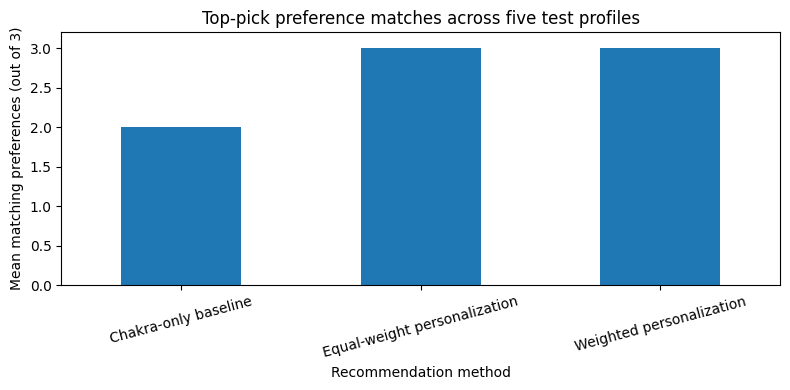

Saved three_method_comparison.png, three_method_results.csv, and three_method_summary.csv


In [10]:
import matplotlib.pyplot as plt
ax = summary.plot.bar(x="Method", y="Mean Top-Pick Matches (0-3)", legend=False, rot=15, figsize=(8, 4))
ax.set_ylabel("Mean matching preferences (out of 3)")
ax.set_xlabel("Recommendation method")
ax.set_ylim(0, 3.2)
ax.set_title("Top-pick preference matches across five test profiles")
plt.tight_layout()
plt.savefig("three_method_comparison.png", dpi=180, bbox_inches="tight")
plt.show()
three_method_results.to_csv("three_method_results.csv", index=False)
summary.to_csv("three_method_summary.csv", index=False)
print("Saved three_method_comparison.png, three_method_results.csv, and three_method_summary.csv")


## 10. Reproducibility and limitations

Run all cells top-to-bottom in Python 3 with pandas and matplotlib installed. The 21-record pose table is embedded in this notebook. No model training, train/test split, or fine-tuning occurs: all methods are deterministic hand-written rules. The five evaluation profiles are fixed examples, not an independent population sample. The weighted approach uses unvalidated weights; matching metadata labels does **not** establish pose suitability, safety, or health benefit. Source URLs and manually assigned fields need independent checking. No human-subject study or IRB approval is claimed.
